# Logistic Regression Baseline for UFC Winner Prediction

This notebook builds a baseline logistic regression model using the processed fight datasets.

## Imports: Libraries Used in This Notebook

This code block imports all required packages for:
1. Data loading and manipulation (`pandas`).
2. Plotting (`matplotlib`, `seaborn`).
3. Model building (`Pipeline`, `StandardScaler`, `LogisticRegression`).
4. Model evaluation (`accuracy`, `precision`, `recall`, `F1`, `ROC-AUC`, confusion matrix, and classification report).
5. Saving trained models (`joblib`).

In [1]:
# Imports
from pathlib import Path

import numpy as np

import joblib
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    log_loss,
    roc_auc_score,
    roc_curve,
    confusion_matrix,
    classification_report,
)

## Paths and Data Loading

This code block defines project/data/model paths, reads the train/validation/test processed CSV files, and prints their shapes so you can verify the splits loaded correctly.

In [2]:
# Paths
PROJECT_ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
DATA_DIR = PROJECT_ROOT / "data" / "processed"
MODEL_DIR = PROJECT_ROOT / "models"
MODEL_DIR.mkdir(parents=True, exist_ok=True)

train_path = DATA_DIR / "fights_training.csv"
val_path = DATA_DIR / "fights_validation.csv"
test_path = DATA_DIR / "fights_testing.csv"

train_df = pd.read_csv(train_path)
val_df = pd.read_csv(val_path)
test_df = pd.read_csv(test_path)


## Define Target Column and the Feature Columns and Split Each Data Frame to X and Y


In [3]:
TARGET = "winner"
dob = "diff_fighter_dob"
features = [col for col in train_df.columns if col != TARGET]

x_train = train_df[features]
y_train = train_df[TARGET]

x_val = val_df[features]
y_val = val_df[TARGET]

x_test = test_df[features]
y_test = test_df[TARGET]


## Build Scikit-Learn Pipline
1. Standarize data to ensure each feature has a mean of zero and a standard deviation of 1 (Standard Scalar)
2. Perform Logistic Regression

In [4]:
pipeline = Pipeline(steps=[("scaler", StandardScaler()),
    ("log_reg", LogisticRegression(random_state=42, max_iter=2000))])
pipeline.fit(x_train, y_train)
val_pred = pipeline.predict(x_val)
val_prob = pipeline.predict_proba(x_val)[:, 1]

# Test predictions
test_pred = pipeline.predict(x_test)
test_prob = pipeline.predict_proba(x_test)[:, 1]


In [5]:
# Save validation-stage predictions and probabilities to CSV
validation_output_path = DATA_DIR / "logistic_regression_validation_predictions.csv"

validation_results = x_val.reset_index(drop=True).copy()
validation_results["actual_label"] = y_val.reset_index(drop=True)
validation_results["predicted_label"] = val_pred
validation_results["prob_fighter_a_win"] = val_prob
validation_results["prob_fighter_b_win"] = 1 - val_prob
validation_results["correct"] = (validation_results["actual_label"] == validation_results["predicted_label"]).astype(int)

validation_results.to_csv(validation_output_path, index=False)
print(f"Saved validation predictions to: {validation_output_path}")

Saved validation predictions to: /Users/andrewmattei/Machine-Learning-Project/data/processed/logistic_regression_validation_predictions.csv


## Metrics and Classification Reports

This code block computes validation and test metrics (accuracy, precision, recall, F1, ROC-AUC, log loss), displays them in a table, and prints class-by-class performance reports.

In [6]:
val_metrics = {
    "accuracy": accuracy_score(y_val, val_pred),
    "precision": precision_score(y_val, val_pred, zero_division=0),
    "recall": recall_score(y_val, val_pred, zero_division=0),
    "f1": f1_score(y_val, val_pred, zero_division=0),
    "log_loss": log_loss(y_val, val_prob),
}

test_metrics = {
    "accuracy": accuracy_score(y_test, test_pred),
    "precision": precision_score(y_test, test_pred, zero_division=0),
    "recall": recall_score(y_test, test_pred, zero_division=0),
    "f1": f1_score(y_test, test_pred, zero_division=0),
    "log_loss": log_loss(y_test, test_prob),
}

metrics_df = pd.DataFrame([val_metrics, test_metrics], index=["validation", "test"])
display(metrics_df)

print("\nValidation classification report:\"")
print(classification_report(y_val, val_pred, digits=4))

print("\nTest classification report:\"")
print(classification_report(y_test, test_pred, digits=4))

,accuracy,precision,recall,f1,log_loss
validation,0.572233,0.572233,0.572233,0.572233,0.684817
test,0.622659,0.622659,0.622659,0.622659,0.658194



Validation classification report:"
              precision    recall  f1-score   support

           0     0.5722    0.5722    0.5722       533
           1     0.5722    0.5722    0.5722       533

    accuracy                         0.5722      1066
   macro avg     0.5722    0.5722    0.5722      1066
weighted avg     0.5722    0.5722    0.5722      1066


Test classification report:"
              precision    recall  f1-score   support

           0     0.6227    0.6227    0.6227      1068
           1     0.6227    0.6227    0.6227      1068

    accuracy                         0.6227      2136
   macro avg     0.6227    0.6227    0.6227      2136
weighted avg     0.6227    0.6227    0.6227      2136



## Cross-Entropy Evaluation and Visualization

This section computes per-fight cross entropy from the predicted probabilities and compares the validation and test distributions. Lower values indicate better calibrated predictions.

,split,mean,median,std
0,test,0.658194,0.611052,0.282353
1,validation,0.684817,0.638743,0.409997


/var/folders/ll/p6v0dbfd42s1q36h2j0fz5kw0000gn/T/ipykernel_44314/3070984650.py:30: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data=ce_df, x="split", y="cross_entropy", inner="quartile", palette="Blues", ax=axes[0])
/var/folders/ll/p6v0dbfd42s1q36h2j0fz5kw0000gn/T/ipykernel_44314/3070984650.py:35: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=validation_ce, x="correct", y="cross_entropy", palette="Set2", ax=axes[1])


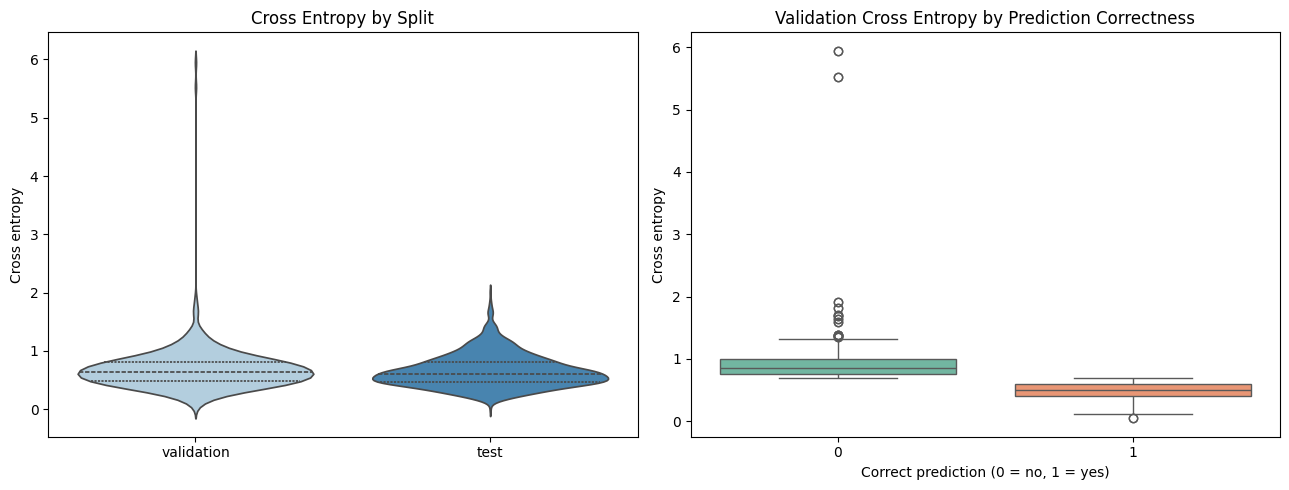

In [7]:
def binary_cross_entropy(y_true, y_prob):
    y_true_arr = np.asarray(y_true, dtype=float)
    y_prob_arr = np.clip(np.asarray(y_prob, dtype=float), 1e-15, 1 - 1e-15)
    return -(y_true_arr * np.log(y_prob_arr) + (1 - y_true_arr) * np.log(1 - y_prob_arr))

validation_ce = pd.DataFrame({
    "split": "validation",
    "actual_label": y_val.reset_index(drop=True),
    "predicted_label": val_pred,
    "prob_fighter_a_win": val_prob,
})
validation_ce["cross_entropy"] = binary_cross_entropy(validation_ce["actual_label"], validation_ce["prob_fighter_a_win"])
validation_ce["correct"] = (validation_ce["actual_label"] == validation_ce["predicted_label"]).astype(int)

test_ce = pd.DataFrame({
    "split": "test",
    "actual_label": y_test.reset_index(drop=True),
    "predicted_label": test_pred,
    "prob_fighter_a_win": test_prob,
})
test_ce["cross_entropy"] = binary_cross_entropy(test_ce["actual_label"], test_ce["prob_fighter_a_win"])
test_ce["correct"] = (test_ce["actual_label"] == test_ce["predicted_label"]).astype(int)

ce_df = pd.concat([validation_ce, test_ce], ignore_index=True)
summary_df = ce_df.groupby("split")["cross_entropy"].agg(["mean", "median", "std"]).reset_index()
display(summary_df)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.violinplot(data=ce_df, x="split", y="cross_entropy", inner="quartile", palette="Blues", ax=axes[0])
axes[0].set_title("Cross Entropy by Split")
axes[0].set_xlabel("")
axes[0].set_ylabel("Cross entropy")

sns.boxplot(data=validation_ce, x="correct", y="cross_entropy", palette="Set2", ax=axes[1])
axes[1].set_title("Validation Cross Entropy by Prediction Correctness")
axes[1].set_xlabel("Correct prediction (0 = no, 1 = yes)")
axes[1].set_ylabel("Cross entropy")

plt.tight_layout()
plt.show()

## ROC-AUC Evaluation and ROC Curve

This section reports ROC-AUC for validation and test splits and plots both ROC curves. Curves closer to the top-left corner indicate stronger class separation.

Validation ROC-AUC: 0.6244
Test ROC-AUC: 0.6532


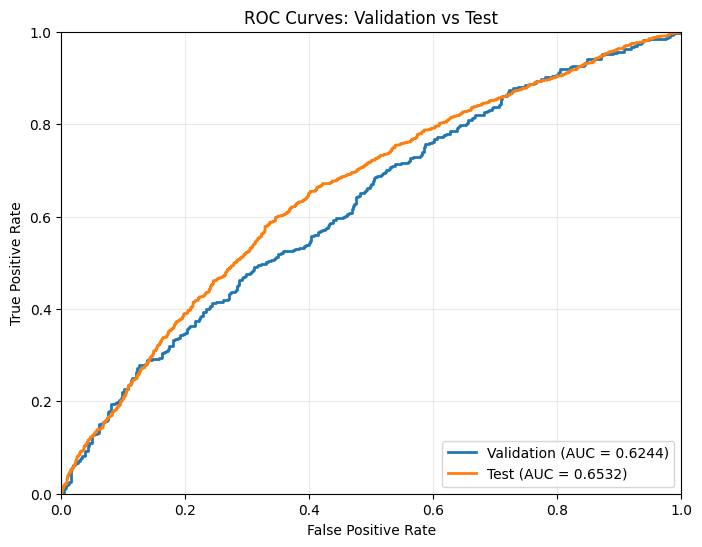

In [12]:
val_auc = roc_auc_score(y_val, val_prob)
test_auc = roc_auc_score(y_test, test_prob)

print(f"Validation ROC-AUC: {val_auc:.4f}")
print(f"Test ROC-AUC: {test_auc:.4f}")

val_fpr, val_tpr, _ = roc_curve(y_val, val_prob)
test_fpr, test_tpr, _ = roc_curve(y_test, test_prob)

plt.figure(figsize=(8, 6))
plt.plot(val_fpr, val_tpr, linewidth=2, label=f"Validation (AUC = {val_auc:.4f})")
plt.plot(test_fpr, test_tpr, linewidth=2, label=f"Test (AUC = {test_auc:.4f})")
plt.xlim(0, 1)
plt.ylim(0, 1)
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curves: Validation vs Test")
plt.legend(loc="lower right")
plt.grid(alpha=0.25)
plt.show()

## Evaluation and Coefficient Interpretation

The next code block does two things:
1. Plots the confusion matrix on the test set so you can see true/false predictions by class.
2. Extracts logistic regression coefficients and displays the top features by absolute magnitude to highlight the strongest model signals.

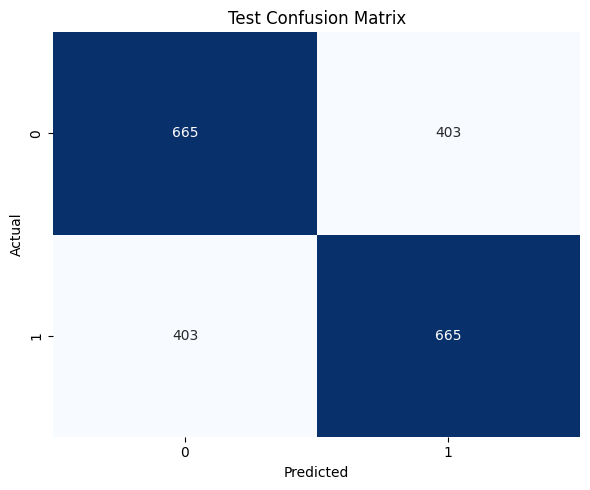

Top 15 features by absolute coefficient:


,feature,coefficient,abs_coef
20,diff_tot_strike_atts,-0.957890,0.957890
21,diff_tot_strikes,0.510566,0.510566
37,diff_ground_atts,0.379732,0.379732
15,diff_fighter_dob,0.319941,0.319941
29,diff_body_strike_atts,0.218704,0.218704
30,diff_body_strikes,-0.216024,0.216024
38,diff_grounds,-0.190193,0.190193
31,diff_leg_strike_atts,0.182702,0.182702
42,diff_losses,-0.168277,0.168277
18,diff_sig_strike_atts,0.159475,0.159475


In [9]:
cm = confusion_matrix(y_test, test_pred)

plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False)
plt.title("Test Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.tight_layout()
plt.show()

coef = pipeline.named_steps["log_reg"].coef_[0]
coef_df = pd.DataFrame({"feature": features, "coefficient": coef})
coef_df["abs_coef"] = coef_df["coefficient"].abs()

print("Top 15 features by absolute coefficient:")
display(coef_df.sort_values("abs_coef", ascending=False).head(15))

## Feature-Focused Accuracy Plots

This code block builds feature-level diagnostics from top coefficients by plotting accuracy across value bins for top features on the test set.
- Bins are ranges of data values grouped together to calculate model accuracy for samples in each group.

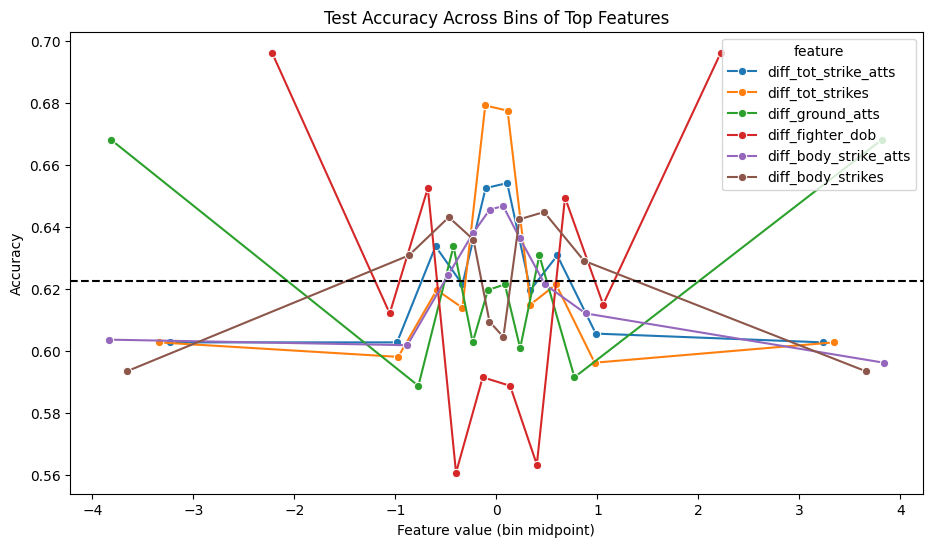

In [10]:
# Top n features for focused accuracy plots
top_n = 6
top_features = coef_df.sort_values("abs_coef", ascending=False).head(top_n)["feature"].tolist()

# Accuracy by feature bins on the test set
plot_df = x_test[top_features].copy()
plot_df["correct"] = (test_pred == y_test.to_numpy()).astype(int)

binned_rows = []
for feature in top_features:
    try:
        bins = pd.qcut(plot_df[feature], q=10, duplicates="drop")
    except ValueError:
        continue

    feature_bins = pd.DataFrame({"bin": bins, "correct": plot_df["correct"]})
    summary = feature_bins.groupby("bin", observed=False)["correct"].mean().reset_index(name="accuracy")
    summary["feature"] = feature
    summary["bin_mid"] = summary["bin"].apply(lambda interval: interval.mid)
    binned_rows.append(summary)

if binned_rows:
    binned_accuracy = pd.concat(binned_rows, ignore_index=True)

    plt.figure(figsize=(11, 6))
    sns.lineplot(data=binned_accuracy, x="bin_mid", y="accuracy", hue="feature", marker="o")
    plt.axhline(accuracy_score(y_test, test_pred), color="black", linestyle="--", label="Overall test accuracy")
    plt.title("Test Accuracy Across Bins of Top Features")
    plt.xlabel("Feature value (bin midpoint)")
    plt.ylabel("Accuracy")
    plt.show()
else:
    print("Could not build binned feature plot (insufficient unique values).")

## Save the Trained Model

The next code block defines the output path for the trained logistic regression model and saves it as a `.joblib` artifact for reuse in later notebooks or scripts.

In [11]:
model_path = MODEL_DIR / "logistic_regression_baseline.joblib"
# joblib.dump(pipeline, model_path)
print(f"Saved model to: {model_path}")

Saved model to: /Users/andrewmattei/Machine-Learning-Project/models/logistic_regression_baseline.joblib
